# SPARC Galaxy Rotation Curves – Starter Notebook

**Dataset**: [SPARC](https://astroweb.case.edu/SPARC/) (Spitzer Photometry and Accurate Rotation Curves)  
Lelli, McGaugh & Schombert (2016) – 175 nearby late-type galaxies with homogeneous [3.6 µm] photometry and high-quality HI + Hα rotation curves.

This notebook:
1. Downloads the two main machine-readable tables
2. Loads them into clean pandas DataFrames
3. Shows a quick overview and an example rotation-curve plot

You can then explore quality cuts, the radial acceleration relation, mass models, etc.


## 1. Setup & Downloads

In [1]:
import os
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Nice default style (works even if seaborn is not installed)
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")

%matplotlib inline

DATA_DIR = Path("sparc_data")
DATA_DIR.mkdir(exist_ok=True)

BASE_URL = "https://astroweb.case.edu/SPARC/"

FILES = {
    "galaxy_sample": "SPARC_Lelli2016c.mrt",       # Table 1 – galaxy properties
    "mass_models":   "MassModels_Lelli2016c.mrt",  # Table 2 – rotation curves + baryons
}

def download_if_needed(key: str) -> Path:
    """Download a file from the SPARC site if it is not already present."""
    fname = FILES[key]
    local = DATA_DIR / fname
    if not local.exists():
        print(f"Downloading {fname} ...")
        urllib.request.urlretrieve(BASE_URL + fname, local)
        print(f"  → saved to {local}")
    else:
        print(f"Already have {local}")
    return local

sample_path = download_if_needed("galaxy_sample")
models_path = download_if_needed("mass_models")


  → saved to sparc_data\SPARC_Lelli2016c.mrt
  → saved to sparc_data\MassModels_Lelli2016c.mrt


## 2. Load Galaxy Sample (Table 1)

The `.mrt` files contain a long descriptive header followed by the data.  
We locate the first real data line (the galaxy “CamB”) and read from there.


In [2]:
def load_sparc_table1(path: Path) -> pd.DataFrame:
    """Load SPARC Table 1 (galaxy sample properties)."""
    with open(path, "r") as f:
        lines = f.readlines()

    # Data begins at the first occurrence of the galaxy "CamB"
    data_start = next(i for i, line in enumerate(lines) if line.lstrip().startswith("CamB"))

    colnames = [
        "Galaxy", "T", "D", "e_D", "f_D", "Inc", "e_Inc",
        "L36", "e_L36", "Reff", "SBeff", "Rdisk", "SBdisk",
        "MHI", "RHI", "Vflat", "e_Vflat", "Q", "Ref"
    ]

    df = pd.read_csv(
        path,
        skiprows=data_start,
        sep=r"\s+",
        names=colnames,
        engine="python",
        na_values=["---"]
    )
    df["Galaxy"] = df["Galaxy"].str.strip()
    return df

galaxies = load_sparc_table1(sample_path)
print(f"Loaded {len(galaxies)} galaxies\n")
galaxies.head(8)


Loaded 175 galaxies



,Galaxy,T,D,e_D,f_D,Inc,e_Inc,L36,e_L36,Reff,SBeff,Rdisk,SBdisk,MHI,RHI,Vflat,e_Vflat,Q,Ref
0,CamB,10,3.36,0.26,2,65.0,5.0,0.075,0.003,1.21,7.89,0.47,66.20,0.012,1.21,0.0,0.0,2,Bm03
1,D512-2,10,15.20,4.56,1,56.0,10.0,0.325,0.022,2.37,9.22,1.24,93.94,0.081,0.00,0.0,0.0,2,Tr09
2,D564-8,10,8.79,0.28,2,63.0,7.0,0.033,0.004,0.72,10.11,0.61,21.13,0.029,0.00,0.0,0.0,2,Tr09
3,D631-7,10,7.72,0.18,2,59.0,3.0,0.196,0.009,1.22,20.93,0.70,115.04,0.290,0.00,57.7,2.7,1,"Tr09,dB01"
4,DDO064,10,6.80,2.04,1,60.0,5.0,0.157,0.007,1.20,17.41,0.69,151.65,0.211,3.49,46.1,3.9,1,"dB02,Sw02"
5,DDO154,10,4.04,0.20,2,64.0,3.0,0.053,0.002,0.65,19.99,0.37,71.26,0.275,4.96,47.0,1.0,2,"Be91,CB89"
6,DDO161,10,7.50,2.25,1,70.0,10.0,0.548,0.015,2.04,20.74,1.22,169.37,1.378,10.69,66.3,1.9,1,Co00
7,DDO168,10,4.25,0.21,2,63.0,6.0,0.191,0.005,1.29,18.23,1.02,92.22,0.413,4.30,53.4,1.9,2,"Sa96,Br92"


In [3]:
# Quick look at the sample
display_cols = ["Galaxy", "T", "D", "L36", "MHI", "Vflat", "Q"]
print(galaxies[display_cols].describe(include="all").T.round(2))
print("\nQuality flag distribution (1 = high, 2 = medium, 3 = low):")
print(galaxies["Q"].value_counts().sort_index())


        count unique   top freq        mean        std    min     25%    50%  \
Galaxy    175    175  CamB    1         NaN        NaN    NaN     NaN    NaN   
T       175.0    NaN   NaN  NaN    6.782857   2.916214    0.0     4.0    7.0   
D       175.0    NaN   NaN  NaN   25.094229  26.773608   0.98   7.255   16.5   
L36     175.0    NaN   NaN  NaN   51.284109   92.67138  0.012   0.978  3.889   
MHI     175.0    NaN   NaN  NaN     4.70612   7.558743  0.012  0.6415  1.701   
Vflat   175.0    NaN   NaN  NaN  104.386286  84.799806    0.0   35.75   88.1   
Q       175.0    NaN   NaN  NaN    1.502857   0.623987    1.0     1.0    1.0   

            75%      max  
Galaxy      NaN      NaN  
T           9.5     11.0  
D          28.7    127.8  
L36     71.1395  489.955  
MHI        4.48   40.075  
Vflat     166.2    332.0  
Q           2.0      3.0  

Quality flag distribution (1 = high, 2 = medium, 3 = low):
Q
1    99
2    64
3    12
Name: count, dtype: int64


## 3. Load Mass Models / Rotation Curves (Table 2)

Every radial point for every galaxy: observed velocity plus the contributions from gas, stellar disk, and bulge (the latter two for $M/L = 1$ at 3.6 µm).


In [4]:
def load_sparc_table2(path: Path) -> pd.DataFrame:
    """Load SPARC Table 2 (rotation curves + baryonic contributions)."""
    with open(path, "r") as f:
        lines = f.readlines()

    data_start = next(i for i, line in enumerate(lines) if line.lstrip().startswith("CamB"))

    colnames = [
        "Galaxy", "D", "R", "Vobs", "e_Vobs",
        "Vgas", "Vdisk", "Vbul", "SBdisk", "SBbul"
    ]

    df = pd.read_csv(
        path,
        skiprows=data_start,
        sep=r"\s+",
        names=colnames,
        engine="python",
        na_values=["---"]
    )
    df["Galaxy"] = df["Galaxy"].str.strip()
    return df

rc = load_sparc_table2(models_path)
print(f"Loaded {len(rc):,} radial points across {rc['Galaxy'].nunique()} galaxies\n")
rc.head(6)


Loaded 3,391 radial points across 175 galaxies



,Galaxy,D,R,Vobs,e_Vobs,Vgas,Vdisk,Vbul,SBdisk,SBbul
0,CamB,3.36,0.16,1.99,1.5,1.86,3.75,0.0,30.32,0.0
1,CamB,3.36,0.41,4.84,1.5,4.24,9.47,0.0,23.77,0.0
2,CamB,3.36,0.57,6.79,1.5,5.61,11.76,0.0,15.87,0.0
3,CamB,3.36,0.73,8.87,1.5,6.77,13.72,0.0,12.40,0.0
4,CamB,3.36,0.90,10.90,1.5,7.77,14.80,0.0,9.63,0.0
5,CamB,3.36,1.06,12.90,1.5,8.44,15.24,0.0,5.86,0.0


## 4. Example Rotation Curve Plot

Change the galaxy name below to explore different objects.  
Well-known examples: `NGC2403`, `NGC3198`, `UGC2885`, `DDO154`, `NGC6503`.


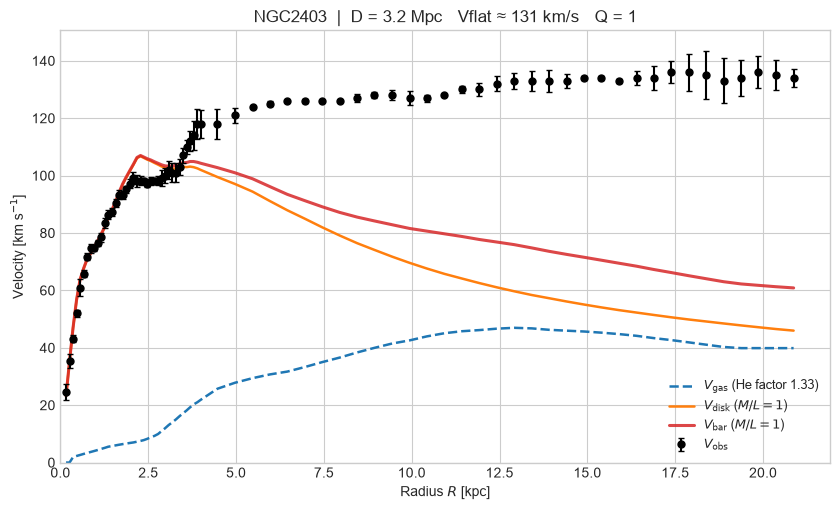

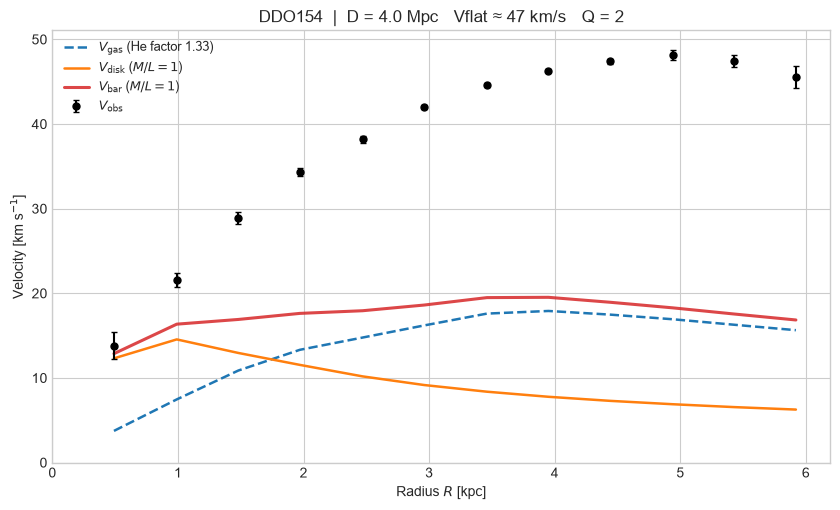

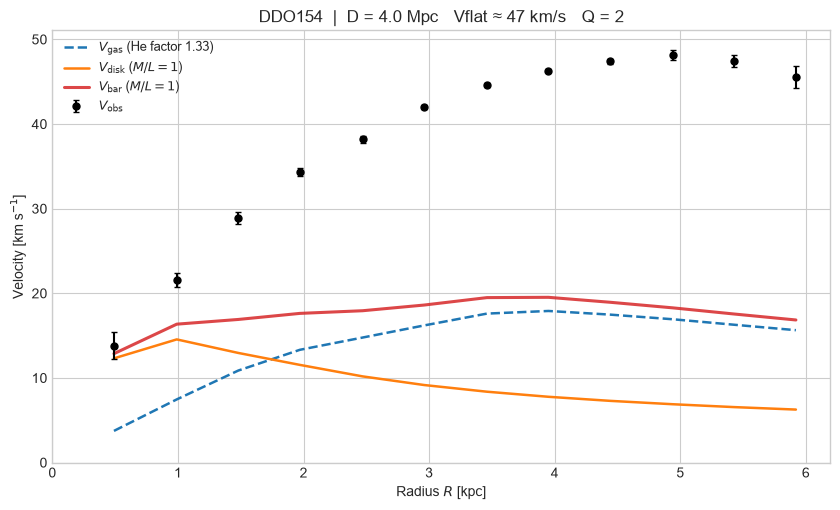

In [9]:
def plot_galaxy(name: str, rc_df: pd.DataFrame = rc, galaxies_df: pd.DataFrame = galaxies):
    """Plot observed rotation curve + baryonic components for one galaxy."""
    g = rc_df.query("Galaxy == @name").copy()
    if g.empty:
        print(f'Galaxy "{name}" not found.')
        print("Some available names:", sorted(rc_df["Galaxy"].unique())[:15], "...")
        return

    info = galaxies_df.query("Galaxy == @name")
    title_extra = ""
    if not info.empty:
        row = info.iloc[0]
        title_extra = f"  |  D = {row.D:.1f} Mpc   Vflat ≈ {row.Vflat:.0f} km/s   Q = {int(row.Q)}"

    fig, ax = plt.subplots(figsize=(8.5, 5.2))

    ax.errorbar(
        g["R"], g["Vobs"], yerr=g["e_Vobs"],
        fmt="o", color="k", ms=5, capsize=2, label=r"$V_{\rm obs}$", zorder=5
    )

    ax.plot(g["R"], g["Vgas"],  "--", color="C0", lw=1.8, label=r"$V_{\rm gas}$ (He factor 1.33)")
    ax.plot(g["R"], g["Vdisk"], "-",  color="C1", lw=1.8, label=r"$V_{\rm disk}$ ($M/L=1$)")
    if (g["Vbul"] > 0).any():
        ax.plot(g["R"], g["Vbul"], "-.", color="C2", lw=1.8, label=r"$V_{\rm bul}$ ($M/L=1$)")

    # Simple baryonic total (quadratic sum)
    Vbar = np.sqrt(g["Vgas"]**2 + g["Vdisk"]**2 + g["Vbul"]**2)
    ax.plot(g["R"], Vbar, color="C3", lw=2.2, alpha=0.85, label=r"$V_{\rm bar}$ ($M/L=1$)")

    ax.set_xlabel("Radius $R$ [kpc]")
    ax.set_ylabel("Velocity [km s$^{-1}$]")
    ax.set_title(f"{name}{title_extra}")
    ax.legend(loc="best", fontsize=9)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    plt.tight_layout()
    plt.show()


# --- pick a galaxy ---
plot_galaxy("NGC2403")
plot_galaxy("DDO154")
plot_galaxy("DDO154")


## 5. Suggested Next Steps

- **Mass-to-light ratio**: Scale `Vdisk` and `Vbul` by $\sqrt{\Upsilon_*}$ (typical $\Upsilon_* \approx 0.5\,M_\odot/L_\odot$ at 3.6 µm).
- **Radial Acceleration Relation (RAR)**: compute $g_{\rm obs} = V_{\rm obs}^2/R$ versus $g_{\rm bar}$.
- Quality cuts: keep only `Q == 1` galaxies.
- Download the full per-galaxy files if needed (`Rotmod_LTG.zip` and `sfb_LTG.zip` are also on the SPARC site).
- Fit simple dark-matter halos or test modified-dynamics prescriptions.

Happy exploring!


In [10]:
# MOND constants and helpers
A0 = 1.2e-10          # m s^-2  (standard value)
KPC_TO_M = 3.085677581e19
KM_TO_M = 1e3

def mond_simple(gN, a0=A0):
    """
    Simple interpolating function (often used):
    g = gN / (1 - exp(-sqrt(gN/a0)))   (McGaugh form, good for RAR)
    or the algebraic 'simple' function.
    Here we use the popular RAR-inspired form.
    """
    x = np.sqrt(gN / a0)
    # Avoid division by zero / numerical issues
    g = np.where(gN > 0, gN / (1.0 - np.exp(-x)), 0.0)
    return g

def compute_mond_velocity(R_kpc, Vbar_kms, a0=A0):
    """
    Given radius (kpc) and Newtonian baryonic velocity (km/s),
    return the MOND-predicted velocity (km/s).
    """
    R_m = R_kpc * KPC_TO_M
    Vbar_ms = Vbar_kms * KM_TO_M

    # Newtonian acceleration from baryons (m/s²)
    gN = (Vbar_ms ** 2) / R_m

    # MOND acceleration
    g_mond = mond_simple(gN, a0=a0)

    # Convert back to velocity (km/s)
    V_mond = np.sqrt(g_mond * R_m) / KM_TO_M
    return V_mond

In [11]:
def plot_galaxy(name, rc_df=rc, galaxies_df=galaxies, 
                upsilon=1.0, show_mond=True, a0=A0):
    """
    Plot observed rotation curve + baryonic components + optional MOND prediction.
    
    upsilon : stellar mass-to-light ratio multiplier 
              (applied to Vdisk and Vbul). Default = 1.0 (as in SPARC table).
              Typical values at 3.6 µm are ~0.5.
    """
    g = rc_df.query("Galaxy == @name").copy()
    if g.empty:
        print(f'Galaxy "{name}" not found.')
        return

    # Scale stellar contributions by chosen mass-to-light ratio
    Vdisk = g["Vdisk"] * np.sqrt(upsilon)
    Vbul  = g["Vbul"]  * np.sqrt(upsilon)
    Vgas  = g["Vgas"]

    # Newtonian baryonic total
    Vbar = np.sqrt(Vgas**2 + Vdisk**2 + Vbul**2)

    # MOND prediction
    if show_mond:
        Vmond = compute_mond_velocity(g["R"].values, Vbar.values, a0=a0)

    # --- Plot ---
    info = galaxies_df.query("Galaxy == @name")
    title_extra = ""
    if not info.empty:
        row = info.iloc[0]
        title_extra = f"  |  D = {row.D:.1f} Mpc   Vflat ≈ {row.Vflat:.0f} km/s   Q = {int(row.Q)}"

    fig, ax = plt.subplots(figsize=(9, 5.5))

    # Observed
    ax.errorbar(g["R"], g["Vobs"], yerr=g["e_Vobs"],
                fmt="o", color="k", ms=5, capsize=2, 
                label=r"$V_{\rm obs}$", zorder=5)

    # Baryonic pieces
    ax.plot(g["R"], Vgas,  "--", color="C0", lw=1.6, label=r"$V_{\rm gas}$")
    ax.plot(g["R"], Vdisk, "-",  color="C1", lw=1.6, label=fr"$V_{{\rm disk}}$ ($\Upsilon_*={upsilon}$)")
    if (Vbul > 0).any():
        ax.plot(g["R"], Vbul, "-.", color="C2", lw=1.6, label=r"$V_{\rm bul}$")

    ax.plot(g["R"], Vbar, color="C3", lw=2.0, alpha=0.8, 
            label=r"$V_{\rm bar}$ (Newtonian)")

    # MOND
    if show_mond:
        ax.plot(g["R"], Vmond, color="C4", lw=2.5, 
                label=fr"MOND ($a_0={a0:.1e}$ m s$^{{-2}}$)")

    ax.set_xlabel("Radius $R$ [kpc]")
    ax.set_ylabel("Velocity [km s$^{-1}$]")
    ax.set_title(f"{name}{title_extra}")
    ax.legend(loc="best", fontsize=9)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    plt.tight_layout()
    plt.show()

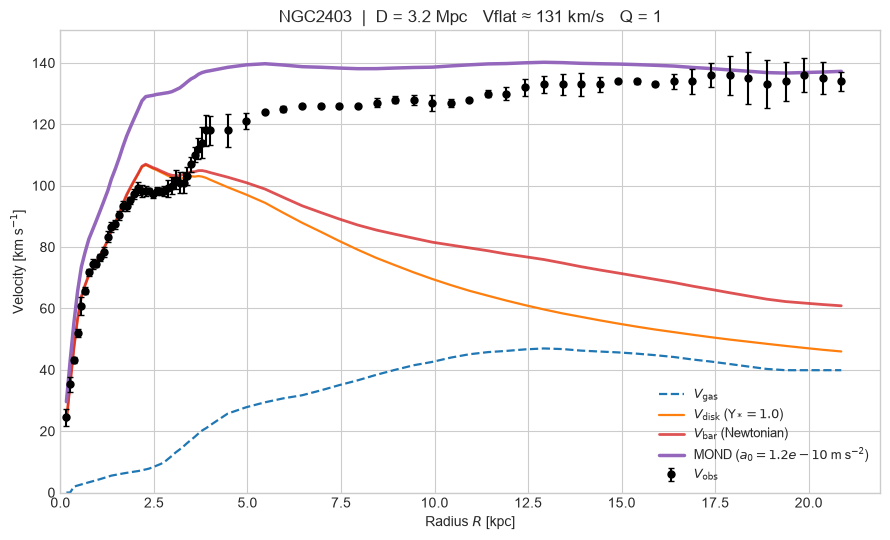

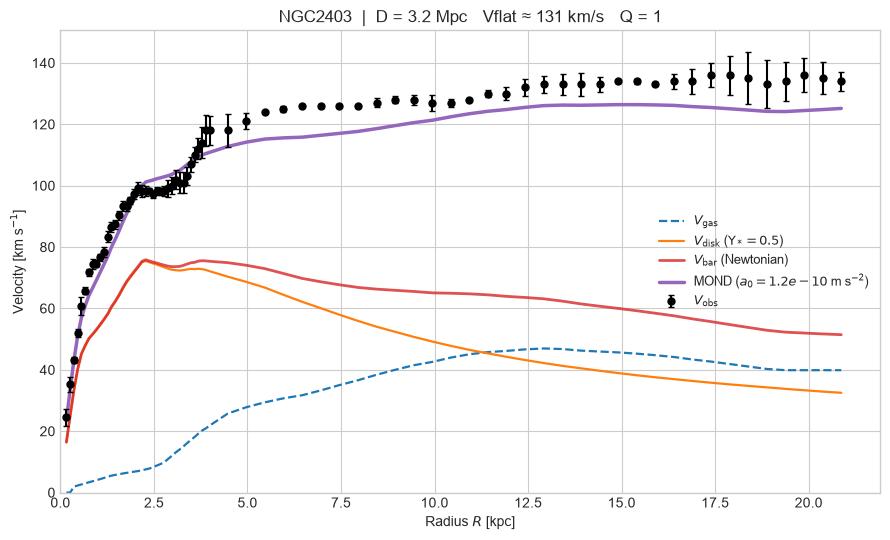

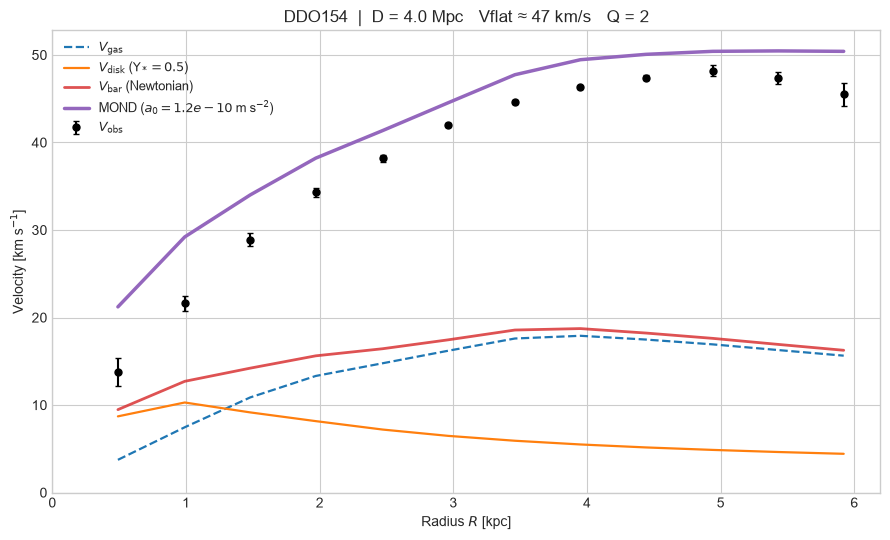

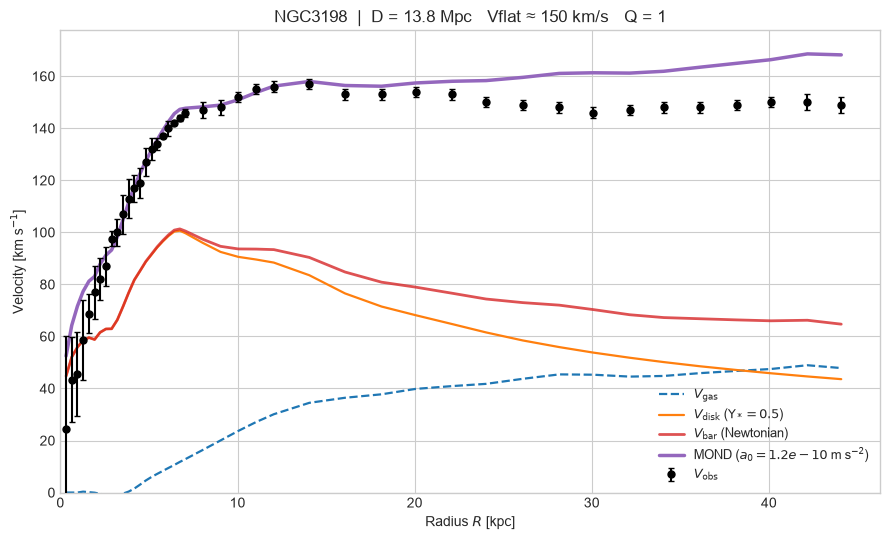

In [12]:
# Default (Upsilon = 1.0, as tabulated)
plot_galaxy("NGC2403")

# More realistic stellar M/L ≈ 0.5 at 3.6 µm
plot_galaxy("NGC2403", upsilon=0.5)

# Try a different galaxy
plot_galaxy("DDO154", upsilon=0.5)
plot_galaxy("NGC3198", upsilon=0.5)

# Looking at the RAR
addiditonal calculations for Radial Accewleration Rrelation

In [13]:
def compute_rar(rc_df, upsilon=0.5, quality=None):
    """
    Compute g_obs and g_bar for the RAR.
    
    Parameters
    ----------
    rc_df   : the full rotation-curve table
    upsilon : stellar mass-to-light ratio (applied to Vdisk & Vbul)
    quality : optional list/tuple of Q values to keep (e.g. [1] or [1,2])
    
    Returns
    -------
    DataFrame with columns: Galaxy, R, g_obs, g_bar, Vobs, Vbar
    """
    df = rc_df.copy()

    # Optional quality cut via the galaxies table
    if quality is not None:
        good = galaxies.query("Q in @quality")["Galaxy"]
        df = df[df["Galaxy"].isin(good)]

    # Scale stellar contributions
    Vdisk = df["Vdisk"] * np.sqrt(upsilon)
    Vbul  = df["Vbul"]  * np.sqrt(upsilon)
    Vgas  = df["Vgas"]
    Vbar  = np.sqrt(Vgas**2 + Vdisk**2 + Vbul**2)

    R_m   = df["R"].values * KPC_TO_M
    Vobs_ms = df["Vobs"].values * KM_TO_M
    Vbar_ms = Vbar.values * KM_TO_M

    # Accelerations in m s^-2
    g_obs = (Vobs_ms ** 2) / R_m
    g_bar = (Vbar_ms ** 2) / R_m

    out = pd.DataFrame({
        "Galaxy": df["Galaxy"].values,
        "R":      df["R"].values,
        "g_obs":  g_obs,
        "g_bar":  g_bar,
        "Vobs":   df["Vobs"].values,
        "Vbar":   Vbar.values,
    })

    # Remove any zero/negative accelerations (numerical safety)
    out = out[(out["g_obs"] > 0) & (out["g_bar"] > 0)].reset_index(drop=True)
    return out


def plot_rar(rar_df, a0=A0, title_suffix=""):
    """
    Classic log-log Radial Acceleration Relation plot
    with MOND prediction and 1:1 line.
    """
    fig, ax = plt.subplots(figsize=(8, 7))

    # Data points
    ax.scatter(rar_df["g_bar"], rar_df["g_obs"],
               s=8, c="0.4", alpha=0.45, edgecolors="none",
               label="SPARC data", zorder=2)

    # 1:1 line (Newtonian expectation)
    g_ref = np.logspace(-13, -8, 300)
    ax.plot(g_ref, g_ref, "k--", lw=1.2, label="1:1 (Newtonian)", zorder=3)

    # MOND prediction
    g_mond = mond_simple(g_ref, a0=a0)
    ax.plot(g_ref, g_mond, color="C3", lw=2.5,
            label=fr"MOND ($a_0 = {a0:.1e}$ m s$^{{-2}}$)", zorder=4)

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1e-13, 1e-8)
    ax.set_ylim(1e-13, 1e-8)

    ax.set_xlabel(r"$g_{\rm bar}$ [m s$^{-2}$]")
    ax.set_ylabel(r"$g_{\rm obs}$ [m s$^{-2}$]")
    ax.set_title("Radial Acceleration Relation" + title_suffix)
    ax.legend(loc="upper left", fontsize=10)
    ax.set_aspect("equal")
    ax.grid(True, which="both", ls=":", alpha=0.4)

    plt.tight_layout()
    plt.show()

Number of points: 2,134


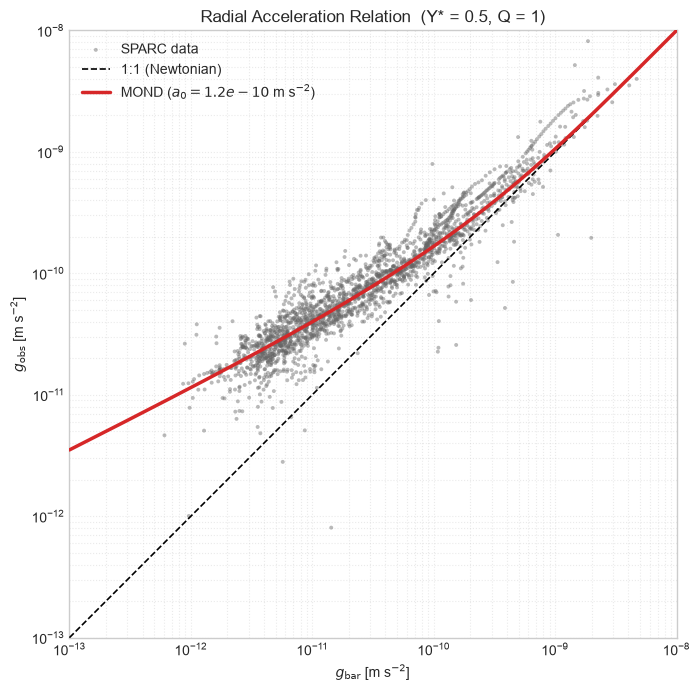

In [14]:
# Recommended: use a realistic stellar M/L and high-quality galaxies
rar = compute_rar(rc, upsilon=0.5, quality=[1])   # Q=1 only
print(f"Number of points: {len(rar):,}")
plot_rar(rar, title_suffix="  (Υ* = 0.5, Q = 1)")

# Compare with all galaxies / different M/L
# rar_all = compute_rar(rc, upsilon=0.5)
# plot_rar(rar_all, title_suffix="  (Υ* = 0.5, all Q)")

# Halo Velocities formula + Simple filter
Now let us look at what the dark matter fits look like

In [15]:
from scipy.optimize import minimize

# Astrophysical G in (km/s)² · kpc / M☉
G_ASTRO = 4.302e-6

def v_nfw(R, rho_s, r_s):
    """NFW circular velocity (km/s). R, r_s in kpc; rho_s in M☉/kpc³."""
    x = R / r_s
    mass = 4 * np.pi * rho_s * r_s**3 * (np.log(1 + x) - x / (1 + x))
    return np.sqrt(G_ASTRO * mass / R)

def v_burkert(R, rho_0, r_0):
    """Burkert (cored) circular velocity (km/s)."""
    x = R / r_0
    # Analytic enclosed mass factor
    factor = (np.log(1 + x) - np.arctan(x) + 0.5 * np.log(1 + x**2))
    mass = 2 * np.pi * rho_0 * r_0**3 * factor   # note the 2π convention common in literature
    # More standard form (equivalent up to normalization of rho_0):
    # mass = 4*np.pi*rho_0*r_0**3 * (0.5*np.log(1+x**2) + np.log(1+x) - np.arctan(x))
    return np.sqrt(np.maximum(G_ASTRO * mass / R, 0.0))

def fit_halo(galaxy_name, halo="nfw", upsilon=0.5, rc_df=rc):
    """
    Fit a dark-matter halo + baryons to one galaxy.
    Returns best-fit parameters and the model curves.
    """
    g = rc_df.query("Galaxy == @galaxy_name").copy()
    if len(g) < 5:
        print("Too few points")
        return None

    R = g["R"].values
    Vobs = g["Vobs"].values
    eV = np.maximum(g["e_Vobs"].values, 1.0)   # floor the errors a bit

    Vgas = g["Vgas"].values
    Vdisk = g["Vdisk"].values * np.sqrt(upsilon)
    Vbul  = g["Vbul"].values  * np.sqrt(upsilon)
    Vbar2 = Vgas**2 + Vdisk**2 + Vbul**2

    def chi2(params):
        if halo == "nfw":
            log_rhos, log_rs = params
            Vh = v_nfw(R, 10**log_rhos, 10**log_rs)
        else:  # burkert
            log_rho0, log_r0 = params
            Vh = v_burkert(R, 10**log_rho0, 10**log_r0)
        Vtot = np.sqrt(Vbar2 + Vh**2)
        return np.sum(((Vobs - Vtot) / eV)**2)

    # Reasonable starting guesses
    if halo == "nfw":
        x0 = [7.5, 1.0]          # log10(rho_s), log10(r_s)
        bounds = [(5, 10), (-0.5, 2.5)]
    else:
        x0 = [7.5, 0.8]
        bounds = [(5, 10), (-0.5, 2.0)]

    res = minimize(chi2, x0, bounds=bounds, method="L-BFGS-B")
    print(f"{galaxy_name}  {halo.upper()}  χ² = {res.fun:.1f}  (dof ≈ {len(R)-2})")

    # Build the best-fit curves
    if halo == "nfw":
        rho_s, r_s = 10**res.x
        Vh = v_nfw(R, rho_s, r_s)
        params = {"rho_s": rho_s, "r_s": r_s}
    else:
        rho_0, r_0 = 10**res.x
        Vh = v_burkert(R, rho_0, r_0)
        params = {"rho_0": rho_0, "r_0": r_0}

    Vtot = np.sqrt(Vbar2 + Vh**2)
    return {
        "R": R, "Vobs": Vobs, "eV": eV,
        "Vbar": np.sqrt(Vbar2), "Vh": Vh, "Vtot": Vtot,
        "params": params, "chi2": res.fun
    }

# 2. Comparison plot (MOND vs NFW vs Burkert)

In [16]:
def plot_comparison(name, upsilon=0.5):
    """Side-by-side visual comparison for one galaxy."""
    g = rc.query("Galaxy == @name")
    if g.empty:
        print("Galaxy not found")
        return

    # Baryons
    Vdisk = g["Vdisk"].values * np.sqrt(upsilon)
    Vbul  = g["Vbul"].values  * np.sqrt(upsilon)
    Vgas  = g["Vgas"].values
    Vbar  = np.sqrt(Vgas**2 + Vdisk**2 + Vbul**2)

    # MOND
    Vmond = compute_mond_velocity(g["R"].values, Vbar, a0=A0)

    # Dark-matter fits
    nfw_fit     = fit_halo(name, halo="nfw",     upsilon=upsilon)
    burkert_fit = fit_halo(name, halo="burkert", upsilon=upsilon)

    # --- Plot ---
    fig, ax = plt.subplots(figsize=(10, 6))

    ax.errorbar(g["R"], g["Vobs"], yerr=g["e_Vobs"],
                fmt="o", color="k", ms=5, capsize=2, label=r"$V_{\rm obs}$", zorder=5)

    ax.plot(g["R"], Vbar,  color="C3", lw=1.8, ls="--", label=r"$V_{\rm bar}$")
    ax.plot(g["R"], Vmond, color="C4", lw=2.5, label="MOND")

    if nfw_fit:
        ax.plot(nfw_fit["R"], nfw_fit["Vtot"], color="C0", lw=2.2, label="Baryons + NFW")
        ax.plot(nfw_fit["R"], nfw_fit["Vh"],   color="C0", lw=1.2, ls=":", alpha=0.7)

    if burkert_fit:
        ax.plot(burkert_fit["R"], burkert_fit["Vtot"], color="C2", lw=2.2, label="Baryons + Burkert")
        ax.plot(burkert_fit["R"], burkert_fit["Vh"],   color="C2", lw=1.2, ls=":", alpha=0.7)

    ax.set_xlabel("Radius [kpc]")
    ax.set_ylabel("Velocity [km/s]")
    ax.set_title(f"{name}   (Υ* = {upsilon})")
    ax.legend(loc="best", fontsize=9)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    plt.tight_layout()
    plt.show()

# Try it on a few galaxies

NGC2403  NFW  χ² = 347.4  (dof ≈ 71)
NGC2403  BURKERT  χ² = 1351.0  (dof ≈ 71)


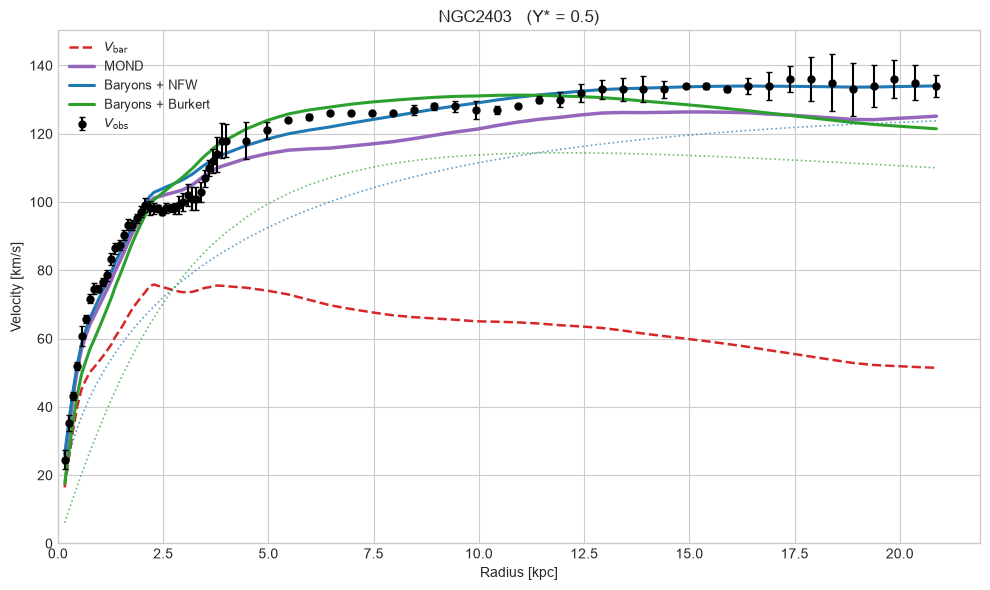

DDO154  NFW  χ² = 51.1  (dof ≈ 10)
DDO154  BURKERT  χ² = 6.9  (dof ≈ 10)


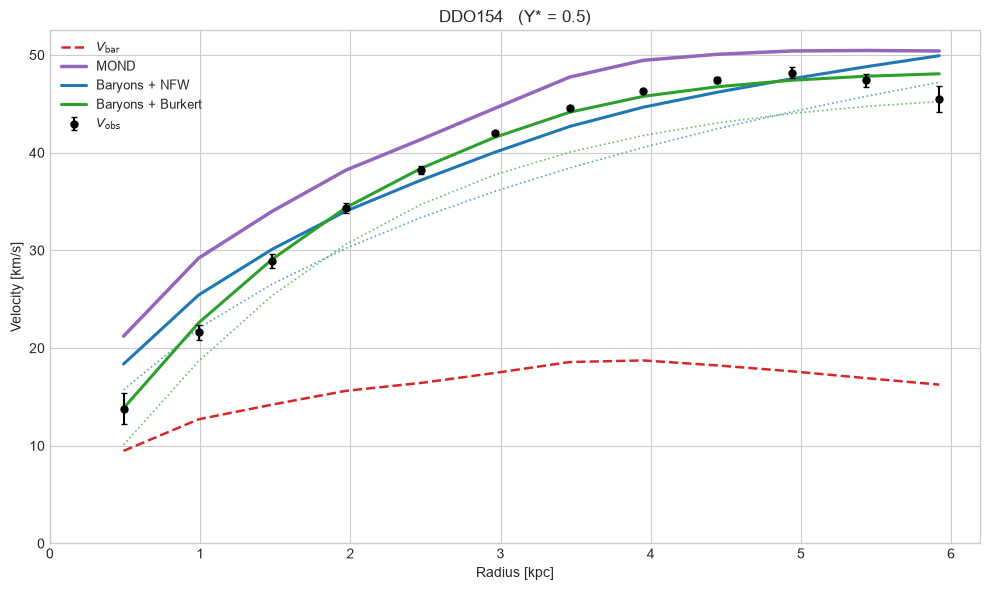

NGC3198  NFW  χ² = 56.4  (dof ≈ 41)
NGC3198  BURKERT  χ² = 69.5  (dof ≈ 41)


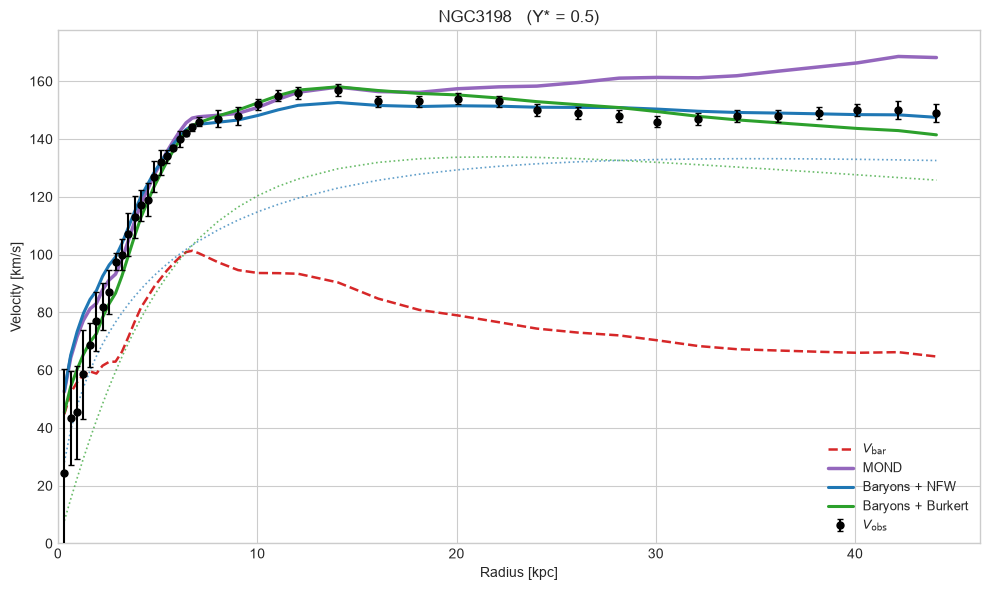

Galaxy not found


In [17]:
# Classic well-behaved spiral
plot_comparison("NGC2403", upsilon=0.5)

# Low-surface-brightness / dwarf (often harder for cuspy NFW)
plot_comparison("DDO154", upsilon=0.5)

# Another common example
plot_comparison("NGC3198", upsilon=0.5)

# High-quality massive spiral
plot_comparison("UGC2885", upsilon=0.5)